# 5. DMRG in practice with TeNPy

**Goal.** You know how DMRG and iDMRG work, from the [pocket course](../docs/pocket-course.html) or notebooks 1 to 4. Now run them with a well-optimized package, [TeNPy](https://github.com/tenpy/tenpy), and learn what to check before you trust its answer. As before, every number is compared with the exact free-fermion result.

This notebook needs TeNPy: `pip install physics-tenpy` (included in the `examples` extra).

*Further reading:* J. Hauschild and F. Pollmann, [arXiv:1805.00055](https://arxiv.org/abs/1805.00055); [SciPost Phys. Lect. Notes 5 (2018)](https://doi.org/10.21468/SciPostPhysLectNotes.5) (lecture notes with TeNPy); J. Hauschild et al., [arXiv:2408.02010](https://arxiv.org/abs/2408.02010); [SciPost Phys. Codebases 41 (2024)](https://doi.org/10.21468/SciPostPhysCodeb.41) (TeNPy version 1).

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from tenpy.algorithms import dmrg as tenpy_dmrg
from tenpy.models.model import CouplingMPOModel
from tenpy.models.tf_ising import TFIChain
from tenpy.networks.mps import MPS
from tenpy.networks.site import SpinHalfSite

import dmrg_from_scratch as dmrg  # only for the exact answers

logging.disable(logging.CRITICAL)  # TeNPy logs every sweep
warnings.filterwarnings("ignore")

## Quick start

To use DMRG on your own model, you write $H$ term by term, and the package builds the MPO. Here is $H = -J\sum_i X_iX_{i+1} - h\sum_i Z_i$:

In [2]:
class TFIM(CouplingMPOModel):
    def init_sites(self, params):
        return SpinHalfSite(conserve=params.get("conserve", None))  # one spin 1/2 per site

    def init_terms(self, params):
        J, h = params.get("J", 1.0), params.get("h", 1.0)
        # The chain is a row of unit cells, each holding one site, called site 0.
        # Put -h Z on site 0 of every unit cell, i.e. -h Z_i on every site i:
        self.add_onsite(-h, 0, "Sigmaz")
        # Put -J X on site 0 of cell i times X on site 0 of cell i + 1, for every i,
        # i.e. -J X_i X_{i+1} on every bond. Arguments: strength, u1, op1, u2, op2, dx.
        # Whether the last site has a partner is up to the boundary condition, not this line.
        self.add_coupling(-J, 0, "Sigmax", 0, "Sigmax", 1)

Two methods define a model:

* `init_sites` says what lives on each site: a spin 1/2, with local dimension $d = 2$. `conserve` will matter later.
* `init_terms` lists the terms of $H$, written once for a **unit cell** and repeated over the whole lattice. TeNPy builds every lattice by repeating a unit cell; our chain's cell holds one site, called site 0.
  * `add_onsite(strength, u, op)` puts `strength * op` on site `u` of every unit cell. Here `u = 0` is the only site, so it is every site.
  * `add_coupling(strength, u1, op1, u2, op2, dx)` puts `strength * op1 op2`, with `op1` on site `u1` of cell $i$ and `op2` on site `u2` of cell $i + $ `dx`, for every $i$. Here: $X$ on site 0 of cell $i$ times $X$ on site 0 of cell $i+1$, which is every nearest-neighbour bond.

  The 0s look redundant with one site per cell. They matter when a cell holds more sites: exercise 1 builds a chain with a different field on even and odd sites.
* `Sigmax` and `Sigmaz` are the Pauli matrices $X$ and $Z$. (TeNPy's `Sx` and `Sz` are $X/2$ and $Z/2$, so mixing them up changes $H$.)

**Boundaries.** "For every $i$" stops at the ends of the chain. By default `CouplingMPOModel` puts the sites on a `Chain` of `L` sites, and its boundary follows `bc_MPS`:

* `bc_MPS="finite"`: an open chain. TeNPy keeps only the bonds whose two sites both exist, $L - 1$ of them; the bond from the last site to "site $L$" is dropped.
* `bc_x="periodic"` (with `bc_MPS="finite"`): a ring. The bond from the last site back to site 0 is added. This bond spans the whole MPS, so the MPO gets bigger.
* `bc_MPS="infinite"`: the unit cell repeats forever, so every site has a right neighbour.

You never handle $i + 1$ going out of range yourself. Print the terms TeNPy made for $L = 4$:

In [3]:
for params in [{"bc_MPS": "finite"}, {"bc_MPS": "finite", "bc_x": "periodic"}]:
    small = TFIM({"L": 4, "h": 1.0, **params})
    print(params, " MPO bond dimensions:", small.H_MPO.chi)
    print(small.all_coupling_terms().to_TermList(), "\n")

{'bc_MPS': 'finite'}  MPO bond dimensions: [2, 3, 3, 3, 2]
-1.00000 * Sigmax_0 Sigmax_1 +
-1.00000 * Sigmax_1 Sigmax_2 +
-1.00000 * Sigmax_2 Sigmax_3 

{'bc_MPS': 'finite', 'bc_x': 'periodic'}  MPO bond dimensions: [2, 3, 4, 4, 2]
-1.00000 * Sigmax_0 Sigmax_1 +
-1.00000 * Sigmax_0 Sigmax_3 +
-1.00000 * Sigmax_1 Sigmax_2 +
-1.00000 * Sigmax_2 Sigmax_3 



The open chain has the three bonds 0–1, 1–2, 2–3; the ring also has 0–3, and its MPO needs one more state to carry the open $X$ of site 0 across the chain. (The outer bonds have 2 states, not the course's 1: TeNPy keeps both "start" and "done" there, and the environments pick one with `IdL` and `IdR`, which is the course's $L = (1,0,0)$ and $R = (0,0,1)$ again.) Now run DMRG on the open chain at the critical point, $L = 100$:

In [4]:
L, h = 100, 1.0
model = TFIM({"L": L, "h": h, "bc_MPS": "finite"})
psi = MPS.from_product_state(model.lat.mps_sites(), ["up"] * L, bc="finite")
info = tenpy_dmrg.run(psi, model, {"trunc_params": {"chi_max": 32, "svd_min": 1e-12}, "mixer": None})

E_exact = dmrg.tfim_open_energy(L, h)
print(f"E = {info['E']:.12f}, exact = {E_exact:.12f}, error = {info['E'] - E_exact:.1e}")

E = -126.961876739597, exact = -126.961876739681, error = 8.4e-11


Four inputs, all from the course:

* `model` holds the MPO of $H$, built from the terms above.
* `psi` is the starting MPS: a product state, all spins up ($\chi = 1$). Two-site DMRG grows $\chi$ by itself, because each split can keep more Schmidt values than came in.
* `chi_max` is $\chi$, the number of Schmidt values each split keeps. `svd_min` also drops any Schmidt value below $10^{-12}$, so $\chi$ stays small where the state does not need it.
* `mixer` adds a small perturbation that helps a sweep escape a poor state (White, [arXiv:cond-mat/0508709](https://arxiv.org/abs/cond-mat/0508709)). Two-site DMRG on this model does not need it, so it is off here. It comes back below.

`run` sweeps until the energy and the entropy stop changing, then returns the energy and statistics; `psi` is overwritten with the ground state.

## The course's objects, by their TeNPy names

| Course | TeNPy |
|---|---|
| MPO tensor $W$ | `model.H_MPO.get_W(i)`, legs `wL, wR, p, p*` |
| boundary vectors $L = (1,0,0)$, $R = (0,0,1)$ | `model.H_MPO.IdL`, `IdR`: the state the MPO starts and ends in |
| right-canonical MPS tensor $B$ | `psi.get_B(i)`, legs `vL, p, vR` |
| Schmidt values on the cut left of site $i$ | `psi.get_SL(i)` |
| bond dimensions | `psi.chi` |
| entanglement entropy of every cut | `psi.entanglement_entropy()`, **natural log** |
| discarded weight | `info["sweep_statistics"]["max_trunc_err"]` |

TeNPy stores tensors with named legs; `.to_ndarray()` gives the plain NumPy array. The $W$ that TeNPy built from our two terms is exactly the $3\times3$ block matrix of the course, with the same leg order $W[w_\text{left}, w_\text{right}, \text{out}, \text{in}]$, and it starts in state 0 and ends in state 2. TeNPy also ships this model ready-made, as `TFIChain` (with the field called `g`); its MPO is the same:

In [5]:
W = model.H_MPO.get_W(50).to_ndarray()
print("same W as ours:", np.allclose(W, dmrg.tfim_bulk_tensor(h)))
print("start state", model.H_MPO.IdL[50], " end state", model.H_MPO.IdR[50])
builtin = TFIChain({"L": L, "g": h, "bc_MPS": "finite", "conserve": None})
print("same MPO as TFIChain:", model.H_MPO.is_equal(builtin.H_MPO))
S = psi.get_SL(50)
print(f"chi = {max(psi.chi)}, middle cut: {len(S)} Schmidt values, sum of squares = {np.sum(S**2):.12f}")

same W as ours: True
start state 0  end state 2
same MPO as TFIChain: True
chi = 32, middle cut: 32 Schmidt values, sum of squares = 1.000000000000


## How good is the answer?

When there is no exact answer, use the discarded weight. As in the course, the energy error tracks it, so a scan over $\chi$ tells you how far you are from converged. Here at $L = 40$:

chi =  4: energy error = 1.8e-03, discarded weight = 1.1e-05


chi =  6: energy error = 4.6e-05, discarded weight = 3.7e-07


chi =  8: energy error = 1.3e-05, discarded weight = 9.4e-08


chi = 12: energy error = 7.3e-08, discarded weight = 6.1e-10


chi = 16: energy error = 1.1e-09, discarded weight = 1.1e-11


chi = 24: energy error = 2.8e-12, discarded weight = 3.5e-14


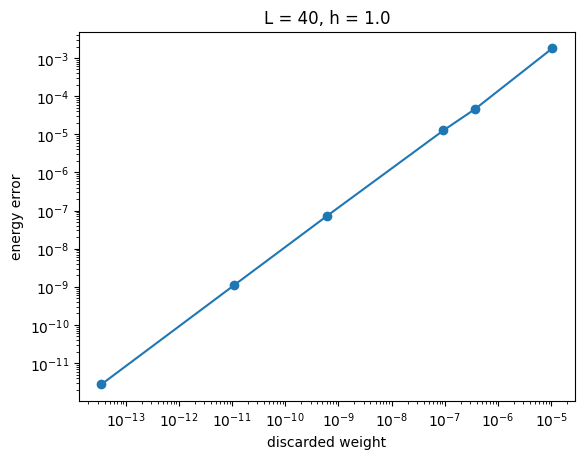

In [6]:
L = 40
model = TFIM({"L": L, "h": h, "bc_MPS": "finite"})
chis, dE, trunc = [4, 6, 8, 12, 16, 24], [], []
for chi in chis:
    psi = MPS.from_product_state(model.lat.mps_sites(), ["up"] * L, bc="finite")
    info = tenpy_dmrg.run(psi, model, {"trunc_params": {"chi_max": chi, "svd_min": 1e-12}, "mixer": None})
    dE.append(info["E"] - dmrg.tfim_open_energy(L, h))
    trunc.append(info["sweep_statistics"]["max_trunc_err"][-1])
    print(f"chi = {chi:2d}: energy error = {dE[-1]:.1e}, discarded weight = {trunc[-1]:.1e}")

plt.loglog(trunc, dE, "o-")
plt.xlabel("discarded weight")
plt.ylabel("energy error")
plt.title(f"L = {L}, h = {h}");

A straight line on a log–log plot: the energy error is proportional to the discarded weight. TeNPy also guards against the worst case: at $\chi = 2$ it stops with an error, because by default it refuses a result whose discarded weight exceeds $10^{-4}$ (the option `max_trunc_err`). To estimate the energy when nothing exact is available, run several $\chi$ and extrapolate the energy to zero discarded weight.

## Entanglement and the central charge

`psi.entanglement_entropy()` gives $S(l)$ for every cut at once. It uses the natural log; divide by $\ln 2$ for bits, as in the course. Fit Calabrese–Cardy to get $c$:

In [7]:
L = 100
model = TFIM({"L": L, "h": h, "bc_MPS": "finite"})
psi = MPS.from_product_state(model.lat.mps_sites(), ["up"] * L, bc="finite")
tenpy_dmrg.run(psi, model, {"trunc_params": {"chi_max": 32, "svd_min": 1e-12}, "mixer": None})
S = psi.entanglement_entropy() / np.log(2)  # bits
c, _ = dmrg.central_charge_fit(L, S)
c_inner, _ = np.polyfit(np.log2(2 * L / np.pi * np.sin(np.pi * np.arange(11, L - 10) / L)), S[10:-10], 1)
print(f"c = {c:.3f} (all cuts), {6 * c_inner:.3f} (10 cuts left out at each end)")

c = 0.533 (all cuts), 0.512 (10 cuts left out at each end)


The same $c \approx 0.53$ and $0.51$ as our own code.

## The ordered phase: which ground state do you get?

At $h = 0.5$ the infinite chain has two ordered ground states, $|\!\to\to\cdots\rangle$ and $|\!\leftarrow\leftarrow\cdots\rangle$ dressed by fluctuations, and any superposition of them is also a ground state. The symmetric one, the cat, has $S = 1$ bit more than either ordered state. Which one the program returns depends on settings that look unrelated: the mixer and the symmetry. Here are iDMRG runs (two-site unit cell, `bc_MPS="infinite"`; more on iDMRG below):

In [8]:
def idmrg(h, chi, conserve=None, mixer=None):
    model = TFIM({"L": 2, "h": h, "bc_MPS": "infinite", "conserve": conserve})
    psi = MPS.from_product_state(model.lat.mps_sites(), ["up"] * 2, bc="infinite")
    info = tenpy_dmrg.run(psi, model, {"trunc_params": {"chi_max": chi, "svd_min": 1e-12}, "mixer": mixer})
    return psi, info["E"]


h = 0.5
m_exact = (1 - h**2) ** (1 / 8)
for conserve, mixer in [(None, None), (None, True), ("parity", True)]:
    psi, e = idmrg(h, 16, conserve, mixer)
    S = psi.entanglement_entropy()[0] / np.log(2)
    m = psi.expectation_value("Sigmax")[0]
    de = e - dmrg.tfim_infinite_energy_density(h)
    print(f"conserve={conserve!s:6} mixer={mixer!s:5}: e - e_exact = {de:+.0e}, S = {S:.4f} bits, |<X>| = {abs(m):.6f}")
print(f"exact magnetization m = {m_exact:.6f}")

conserve=None   mixer=None : e - e_exact = +4e-14, S = 1.0042 bits, |<X>| = 0.000000


conserve=None   mixer=True : e - e_exact = -1e-13, S = 0.0042 bits, |<X>| = 0.964679


conserve=parity mixer=True : e - e_exact = +5e-14, S = 1.0042 bits, |<X>| = 0.000000
exact magnetization m = 0.964679


* With nothing that breaks the symmetry, iDMRG returns the cat ($S \approx 1$ bit, $\langle X\rangle = 0$), as our own iDMRG did.
* The mixer's perturbation is not symmetric, so it tips the state into one ordered state, with $S \approx 0$ and $\langle X\rangle$ equal to the exact magnetization $m = (1-h^2)^{1/8}$ (P. Pfeuty, [Ann. Phys. 57, 79 (1970)](https://doi.org/10.1016/0003-4916(70)90270-8)).
* `conserve="parity"` stores every tensor in blocks of definite parity $\prod_i Z_i$. Then no perturbation can mix the two sectors, and the result is the cat again, whatever the mixer does.

All three are correct ground states, with the exact energy. Decide which one you want before you measure. In the cat, the order shows up in the correlations instead: $\langle X_0 X_r\rangle \to m^2$ at large $r$.

In [9]:
psi, _ = idmrg(h, 16, "parity")
r = np.array([1, 10, 50])
C = psi.correlation_function("Sigmax", "Sigmax", sites1=[0], sites2=r)[0]
for ri, Ci in zip(r, C, strict=True):
    print(f"<X_0 X_{ri}> = {Ci:.10f}")
print(f"m^2        = {m_exact**2:.10f}")

<X_0 X_1> = 0.9342154577
<X_0 X_10> = 0.9306048596
<X_0 X_50> = 0.9306048591
m^2        = 0.9306048591


## The infinite chain

`bc_MPS="infinite"` with `L = 2` is iDMRG on a two-site unit cell, the setup of the course. The energy is per site:

In [10]:
for h in [1.5, 1.0]:
    t = time.perf_counter()
    psi, e = idmrg(h, 16)
    e_exact = dmrg.tfim_infinite_energy_density(h)
    dt = time.perf_counter() - t
    print(f"h = {h}: e - e_exact = {e - e_exact:.1e}, xi = {psi.correlation_length():.1f} sites, {dt:.1f} s")

h = 1.5: e - e_exact = -8.0e-14, xi = 2.4 sites, 0.2 s


h = 1.0: e - e_exact = 5.7e-07, xi = 431.9 sites, 5.2 s


At $h = 1.5$ the energy is exact to machine precision. At $h = 1$ the error is $6\times10^{-7}$ and $\xi \approx 430$, the same as our own iDMRG with $\chi = 16$ (notebook 4). `psi.correlation_length()` is the transfer-matrix correlation length of the course, in sites.

**A trap with symmetries.** With `conserve="parity"` the transfer matrix also splits into parity blocks, and by default `correlation_length` looks only at the even block. The longest correlation, that of $\langle X_0 X_r\rangle$, is in the odd block, since $X$ flips parity. Ask for all blocks with `charge_sector=None`:

In [11]:
psi, _ = idmrg(1.0, 16, "parity")
print(f"even block only: xi = {psi.correlation_length():.1f}")
print(f"all blocks:      xi = {psi.correlation_length(charge_sector=None):.1f}")

even block only: xi = 75.9
all blocks:      xi = 431.7


Finite-entanglement scaling, as in the course: at $h = 1$, $\chi$ sets a finite $\xi$, and $S = (c/6)\log_2\xi + \text{const}$:

c = 0.512


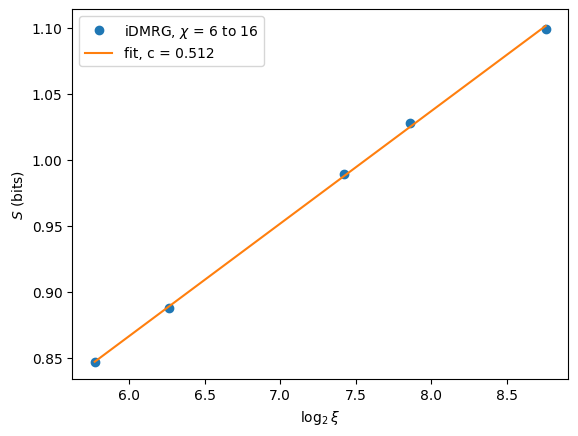

In [12]:
chis, S, xi = [6, 8, 10, 12, 16], [], []
for chi in chis:
    psi, _ = idmrg(1.0, chi)
    S.append(psi.entanglement_entropy()[0] / np.log(2))
    xi.append(psi.correlation_length())
slope, const = np.polyfit(np.log2(xi), S, 1)
print(f"c = {6 * slope:.3f}")
plt.plot(np.log2(xi), S, "o", label="iDMRG, $\\chi$ = 6 to 16")
plt.plot(np.log2(xi), slope * np.log2(xi) + const, "-", label=f"fit, c = {6 * slope:.3f}")
plt.xlabel(r"$\log_2\xi$")
plt.ylabel("$S$ (bits)")
plt.legend();

$c \approx 0.5$, as from our own code.

## What the package adds

The algorithm is the one you know, and the model is the one you wrote. What TeNPy adds is engineering that you would otherwise write yourself:

* **Conserved charges.** Tensors stored in symmetry blocks are smaller and faster, and they let you choose the sector, as above.
* **Single-site DMRG with a mixer**, cheaper than two-site: attaching $L$ or $R$ in a matvec costs $\chi^3 D d$ instead of $\chi^3 D d^2$.
* **Other models and lattices**, including 2D cylinders: the same `add_onsite` and `add_coupling`, on a different lattice.
* **Time evolution** (TEBD, TDVP, MPO evolution) on the same MPS.

What it does not add is a guarantee. The checks are yours: the discarded weight and a scan over $\chi$, convergence between sweeps, and which ground state you got.

## Exercises

1. **Two sites per unit cell.** Give even and odd sites different fields, $H = -J\sum_i X_iX_{i+1} - \sum_i h_i Z_i$ with $h_i = h_\text{even}$ or $h_\text{odd}$. Now the unit cell holds two sites, 0 (even) and 1 (odd), and the bonds come in two kinds: inside a cell, and from one cell into the next:

   ```python
   from tenpy.models.lattice import Lattice


   class AlternatingTFIM(CouplingMPOModel):
       def init_sites(self, params):
           return SpinHalfSite(conserve=None)

       def init_lattice(self, params):
           site = self.init_sites(params)
           # L // 2 unit cells in a row, each holding two sites: 0 at position 0, 1 at position 1
           return Lattice([params["L"] // 2], [site, site], basis=[[2.0]], positions=[[0.0], [1.0]],
                          bc="open", bc_MPS="finite")

       def init_terms(self, params):
           J, h_even, h_odd = params.get("J", 1.0), params["h_even"], params["h_odd"]
           # -h_even Z on site 0 of every cell: sites 0, 2, 4, ...
           self.add_onsite(-h_even, 0, "Sigmaz")
           # -h_odd Z on site 1 of every cell: sites 1, 3, 5, ...
           self.add_onsite(-h_odd, 1, "Sigmaz")
           # -J X on site 0 of cell i times X on site 1 of the same cell (dx = 0): bonds 0-1, 2-3, ...
           self.add_coupling(-J, 0, "Sigmax", 1, "Sigmax", 0)
           # -J X on site 1 of cell i times X on site 0 of cell i + 1 (dx = 1): bonds 1-2, 3-4, ...
           self.add_coupling(-J, 1, "Sigmax", 0, "Sigmax", 1)
   ```

   Run it with `AlternatingTFIM({"L": 40, "h_even": 1.0, "h_odd": 1.0})`. With equal fields it must give `dmrg.tfim_open_energy(40, 1.0)`. Drop the second `add_coupling`: what does the chain fall apart into, and what energy do you get? Then fix `h_odd = 2` and scan `h_even`: where is the entropy of the middle cut largest?
2. **Your own model.** Add a longitudinal field, $-h_x\sum_i X_i$, to `TFIM` with one more `add_onsite`. There is no exact answer now: run $\chi = 8, 16, 32$ and judge convergence from the discarded weight. What happens if you also ask for `conserve="parity"`, and why?
3. **Heisenberg chain.** Write $H = \sum_i \vec S_i\cdot\vec S_{i+1}$ the same way, with `SpinHalfSite(conserve="Sz")` and the terms $S^z S^z + \tfrac12(S^+S^- + S^-S^+)$ (operators `Sz`, `Sp`, `Sm`). Check that its MPO equals TeNPy's `XXZChain` with `Jxx = Jz = 1`, `hz = 0`, then compare the iDMRG energy per site with the Bethe-ansatz value $1/4 - \ln 2$ (L. Hulthén, Ark. Mat. Astron. Fys. 26A, No. 11 (1938)). How does the error change with $\chi$, compared with the TFIM at $h = 1$?
4. **What symmetry buys.** Time the finite run at $L = 100$, $h = 1$, $\chi = 64$ with `conserve=None` and with `conserve="parity"`. Then look at `psi.get_B(50)`: how many blocks does it have, and how big are they?
5. **No exact answer.** Use `tenpy.models.tf_ising.TFIModel` on a `Square` lattice cylinder with circumference 4 at $g = 4$. Run iDMRG for $\chi = 16, 32, 64$ and decide, from the discarded weight alone, how many digits of the energy per site you trust.
6. In the cat state at $h = 0.5$, compute $\langle X_0 X_r\rangle$ for $r$ up to 20 and see how fast it approaches $m^2$. What sets the rate?